In [14]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 1 — Environment Setup
# Mounts Google Drive and defines all folder paths used throughout the notebook.
# This cell must be run first before any other cell.
# ─────────────────────────────────────────────────────────────────────────────

import os
from google.colab import drive

# Connect Google Drive to this Colab session.
# After running, Drive is accessible at /content/drive/MyDrive/
drive.mount('/content/drive')

# Root path of the NEL project on Google Drive.
# All other paths are built from this variable so any team member can run
# this notebook on their own account without changing anything else.
DRIVE = '/content/drive/MyDrive/HNS-RE2SD/Industrial Networking & AI Engineering/4th Year/SEMESTER 08/Project 02/NEL'

# Subfolder paths — each serves a specific purpose in the ML pipeline
DATASETS      = DRIVE + '/nel_datasets'       # CSV dataset files
MODELS        = DRIVE + '/models'             # Trained .pkl model files
PREPROCESSORS = DRIVE + '/notebooks/preprocessors'  # Scaler .pkl files
NOTEBOOKS     = DRIVE + '/notebooks'          # Notebook files

# Create the models and preprocessors folders if they do not exist yet.
# exist_ok=True means no error is raised if the folder already exists.
os.makedirs(MODELS, exist_ok=True)
os.makedirs(PREPROCESSORS, exist_ok=True)

print("✓ Drive mounted")
print("✓ Paths set")
print("✓ Folders ready")

# List all available dataset files to confirm the datasets folder is accessible
print("\nDatasets available:")
for f in os.listdir(DATASETS):
    print(f"  - {f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ Drive mounted
✓ Paths set
✓ Folders ready

Datasets available:
  - dataset_solar.csv
  - dataset_wind.csv
  - dataset_fuelcell.csv
  - dataset_battery.csv
  - dataset_energy_management.csv


In [15]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 2 — Library Installation and Imports
# Installs any missing libraries and imports everything needed for the full
# ML pipeline: data loading, preprocessing, modeling, evaluation, and saving.
# ─────────────────────────────────────────────────────────────────────────────

# Install XGBoost — not pre-installed on all Colab sessions.
# The -q flag runs silently without printing installation logs.
!pip install xgboost -q

# Data manipulation and numerical operations
import pandas as pd       # Loading and processing the CSV dataset
import numpy as np        # Mathematical operations and array handling

# Visualization libraries
import matplotlib.pyplot as plt  # Plotting charts and graphs
import seaborn as sns            # Enhanced statistical visualizations (heatmaps)

# Scikit-learn — machine learning tools
from sklearn.ensemble import RandomForestRegressor   # First model: Random Forest
from sklearn.preprocessing import StandardScaler     # Feature scaling
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Evaluation metrics
from sklearn.model_selection import RandomizedSearchCV  # Hyperparameter tuning (if needed)

# XGBoost — gradient boosting model (typically outperforms Random Forest on tabular data)
import xgboost as xgb

# joblib — used to save and load trained models and scalers as .pkl files
import joblib

# Suppress non-critical warnings to keep output clean
import warnings
warnings.filterwarnings('ignore')

print("✓ All libraries imported successfully")

✓ All libraries imported successfully


Phase 2 — Load Data and EDA

In [16]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 3 — Load Dataset and Initial Inspection (Phase 2: EDA)
# Loads the solar dataset from Google Drive and performs the first inspection
# to understand its structure, data types, and quality before any processing.
# ─────────────────────────────────────────────────────────────────────────────

# Load the solar dataset from the shared Drive folder.
# parse_dates=['timestamp'] automatically converts the timestamp column
# from a string to a proper datetime object for time-based operations.
solarDf = pd.read_csv(DATASETS + '/dataset_solar.csv', parse_dates=['timestamp'])

# Number of rows and columns — expected: ~348,529 rows, 18 columns
print(f"Shape of the dataset: {solarDf.shape}\n")

# List all column names to verify all expected features are present
print(f"Names of the columns: {solarDf.columns.tolist()}\n")

# Data types of each column:
# - timestamp should be datetime64
# - all other columns should be float64 or int64
print(f"Datatypes: \n{solarDf.dtypes}\n")

# Count of missing values per column.
# All values should be 0 — the simulated dataset has no missing values.
# This check becomes critical when working with real NEL station data.
print(f"Missing values: \n{solarDf.isnull().sum()}\n")

# Statistical summary of all numeric columns.
# Used to verify that value ranges are physically realistic:
# - Solar_Rad_Wm2: 0 – 950 W/m²
# - P_SOL_total_W: 0 – 220 W
# - Temperatures: within expected Batna climate ranges
print(f"Basic stats: \n{solarDf.describe()}\n")

Shape of the dataset: (348529, 18)

Names of the columns: ['timestamp', 'Solar_Rad_Wm2', 'T_SOL1_C', 'T_SOL2_C', 'T_outdoor_C', 'tilt_angle_deg', 'azimuth_angle_deg', 'shading_factor', 'V_SOL1_V', 'V_SOL2_V', 'I_SOL_A', 'P_SOL1_W', 'P_SOL2_W', 'P_SOL_total_W', 'V_SOL3_V', 'I_SOL3_A', 'V_Load_V', 'I_Load_A']

Datatypes: 
timestamp            datetime64[ns]
Solar_Rad_Wm2               float64
T_SOL1_C                    float64
T_SOL2_C                    float64
T_outdoor_C                 float64
tilt_angle_deg                int64
azimuth_angle_deg             int64
shading_factor              float64
V_SOL1_V                    float64
V_SOL2_V                    float64
I_SOL_A                     float64
P_SOL1_W                    float64
P_SOL2_W                    float64
P_SOL_total_W               float64
V_SOL3_V                    float64
I_SOL3_A                    float64
V_Load_V                    float64
I_Load_A                    float64
dtype: object

Missing values:

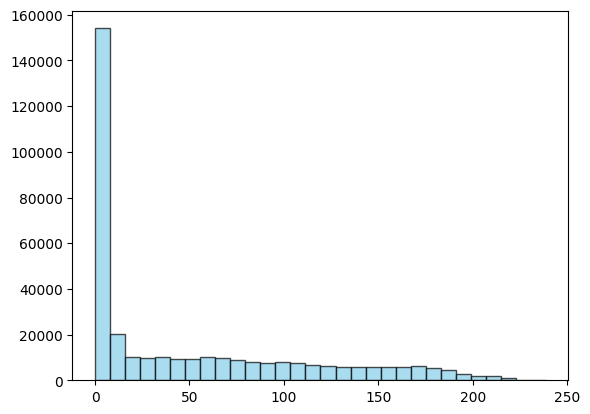

In [17]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 4 — Target Distribution (Phase 2: EDA)
# Plots the distribution of the target variable P_SOL_total_W to understand
# how solar power output is spread across all recorded samples.
# ─────────────────────────────────────────────────────────────────────────────

# Histogram of the target variable P_SOL_total_W (total solar power in Watts).
# Expected shape: right-skewed — most readings are low power (morning/evening/cloudy)
# with fewer readings at high power (midday summer peaks).
# This is physically realistic for a lab that operates 08:00–18:00 year-round.
plt.hist(solarDf["P_SOL_total_W"], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
plt.title("Distribution of P_SOL_total_W (Target Variable)")
plt.xlabel("Total Solar Power Output (W)")
plt.ylabel("Number of Samples")
plt.show()

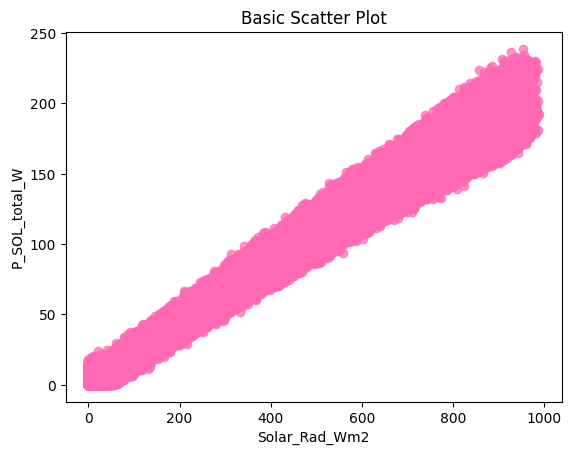

In [18]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 5 — Solar Irradiance vs Power Output (Phase 2: EDA)
# Scatter plot to visualize the relationship between the primary input feature
# (Solar_Rad_Wm2) and the target variable (P_SOL_total_W).
# This is the most important EDA plot for the solar model.
# ─────────────────────────────────────────────────────────────────────────────

# Extract the primary input feature and the target variable for plotting
x = solarDf["Solar_Rad_Wm2"]   # Solar irradiance — primary driver of power output
y = solarDf["P_SOL_total_W"]   # Total solar power output — our prediction target

# Scatter plot: each point represents one 5-minute reading.
# Expected pattern: a near-linear positive relationship — as irradiance increases,
# power output increases proportionally.
# The scatter (spread) around the line is caused by temperature variation,
# shading, and panel angle differences across experimental configurations.
plt.scatter(x, y, color='hotpink', alpha=0.7)
plt.title("Solar Irradiance vs Total Solar Power Output")
plt.xlabel("Solar Irradiance (W/m²)")
plt.ylabel("Total Solar Power Output (W)")
plt.show()

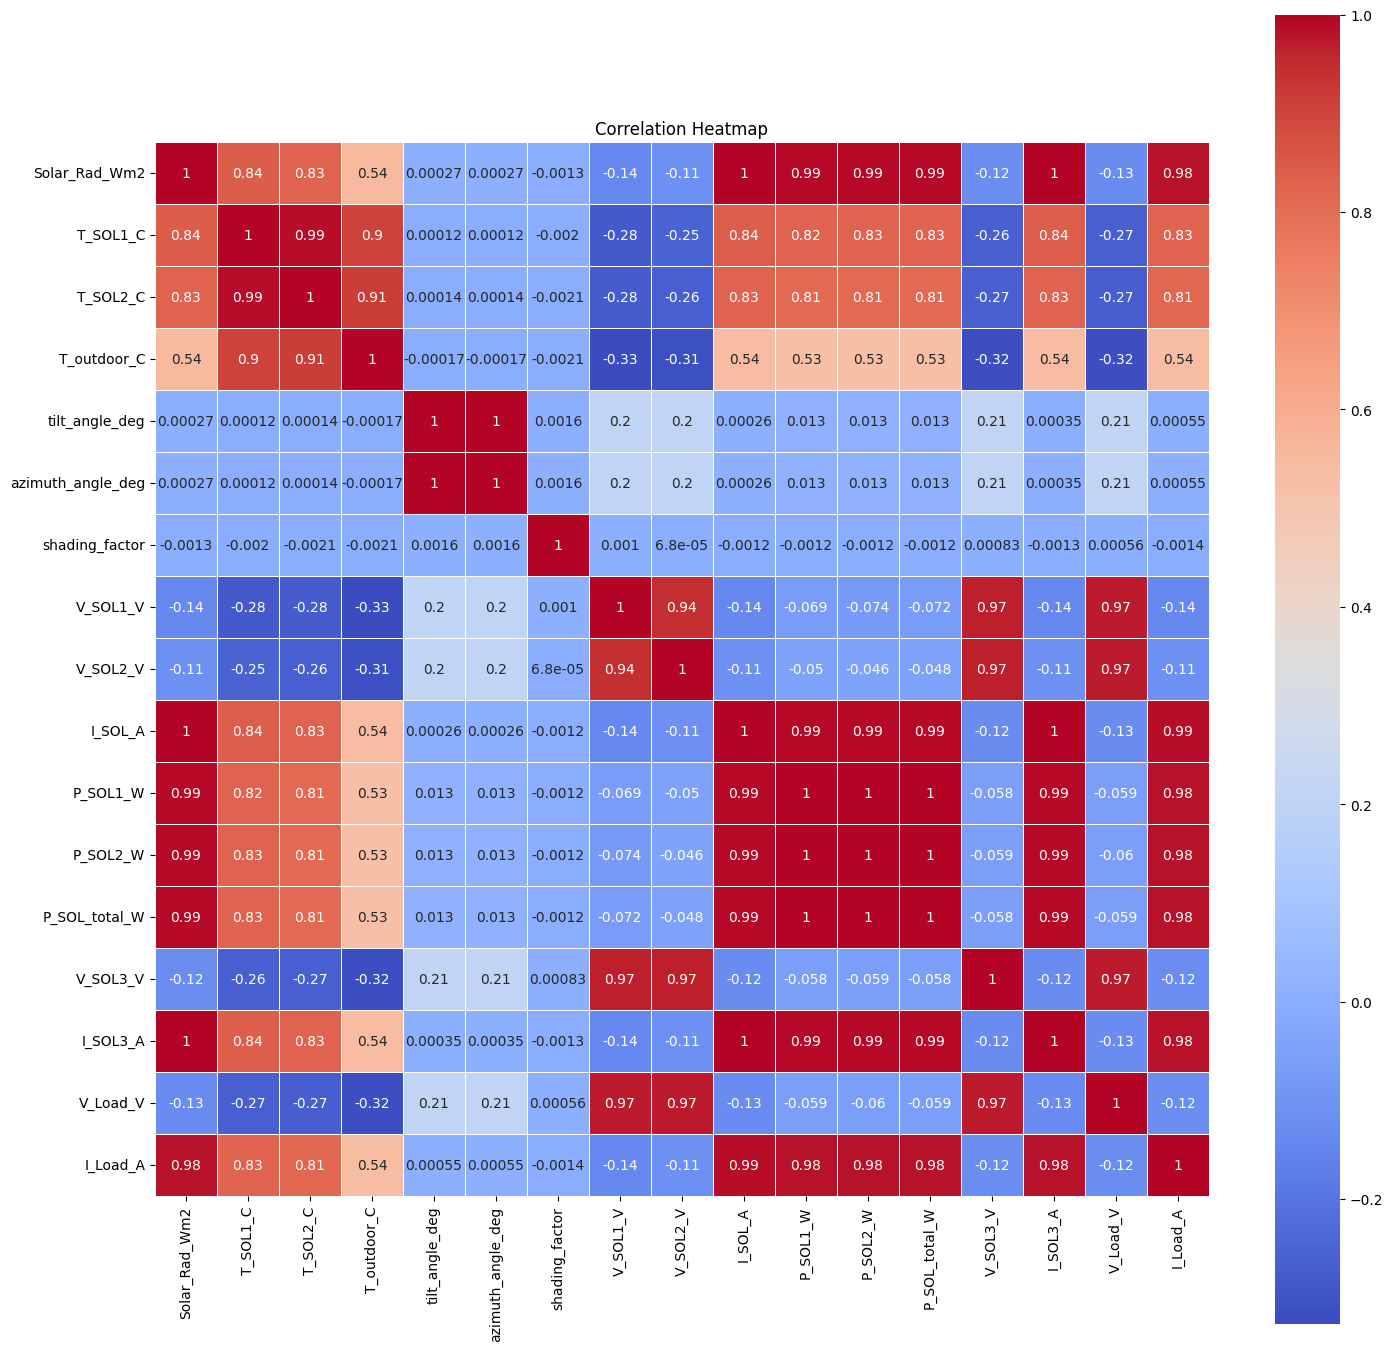

In [19]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 6 — Correlation Heatmap (Phase 2: EDA)
# Computes and visualizes the correlation between all numeric columns.
# Helps identify which features are most related to the target variable
# and which features are redundant (highly correlated with each other).
# ─────────────────────────────────────────────────────────────────────────────

# Compute the Pearson correlation matrix for all numeric columns.
# Values range from -1 to +1:
#   +1 = perfect positive correlation
#    0 = no correlation
#   -1 = perfect negative correlation
# numeric_only=True excludes the timestamp column automatically.
corr_matrix = solarDf.corr(numeric_only=True)

# Plot the correlation matrix as a color-coded heatmap.
# Key things to look for:
#   - Solar_Rad_Wm2 should have the highest correlation with P_SOL_total_W
#   - P_SOL1_W and P_SOL2_W will show near-perfect correlation with P_SOL_total_W
#     (expected — total = panel1 + panel2, but these are excluded from features due to leakage)
#   - Temperature columns will show moderate correlation with each other
plt.figure(figsize=(17, 17))
sns.heatmap(corr_matrix, cmap='coolwarm', annot=True, square=True, linewidths=0.5)
plt.title("Correlation Heatmap — Solar Dataset")
plt.show()

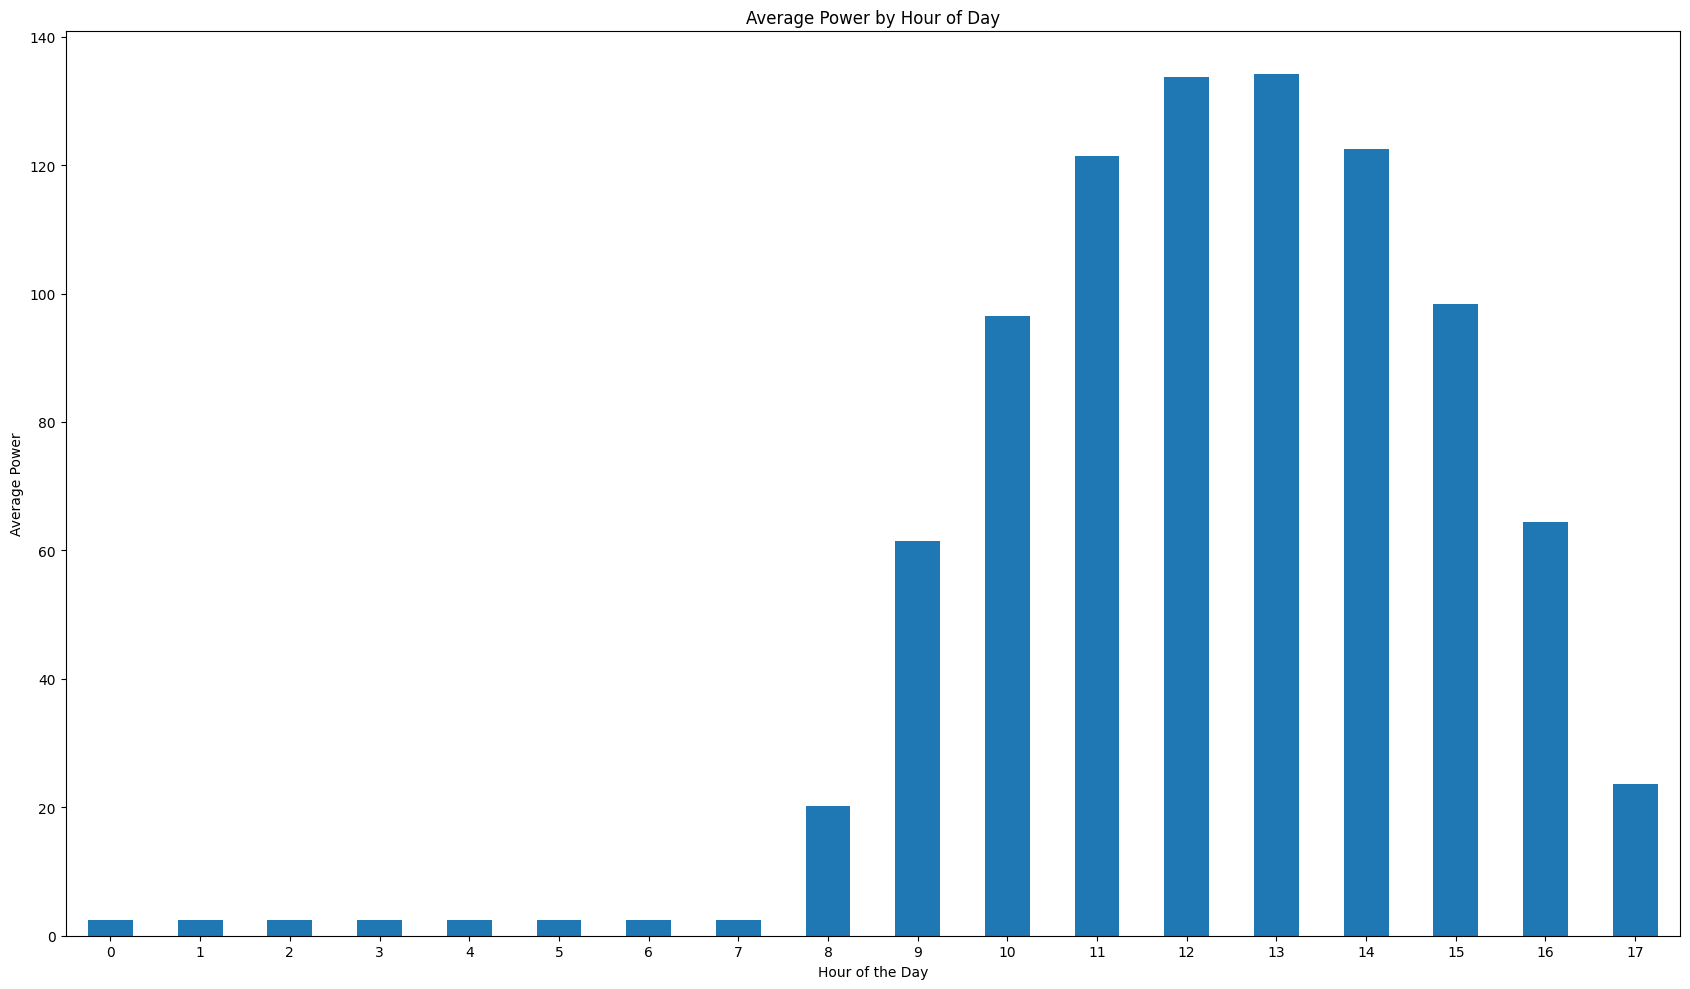

In [21]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 7 — Average Solar Power by Hour of Day (Phase 2: EDA)
# Shows how average solar power output changes throughout the lab day (08:00–18:00).
# This confirms the expected solar arc pattern and validates the time dimension
# of the dataset before engineering cyclic time features.
# ─────────────────────────────────────────────────────────────────────────────

# Group all readings by hour of day and compute the mean power for each hour.
# dt.hour extracts the hour component from the timestamp column.
# This averages across all days and years in the dataset (2020–2026).
avg_power_by_hour = solarDf.groupby(solarDf['timestamp'].dt.hour)['P_SOL_total_W'].mean()

# Bar chart of average power per hour.
# Expected pattern:
#   - Low power at 08:00 (sun just rising, low angle)
#   - Peak power around 12:00–13:00 (sun at highest point)
#   - Decreasing power from 14:00 onwards
#   - This bell-curve shape confirms the dataset correctly models the solar arc
avg_power_by_hour.plot(kind='bar', figsize=(17, 10))
plt.xlabel('Hour of the Day')
plt.ylabel('Average Power Output (W)')
plt.title('Average Solar Power Output by Hour of Day (2020–2026)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Phase 3 — Data Preprocessing

In [22]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 8 — Duplicate Check (Phase 3: Data Preprocessing)
# Checks for duplicate rows in the dataset before any cleaning or transformation.
# Duplicates can cause data leakage between train and test sets and inflate
# model performance metrics artificially.
# ─────────────────────────────────────────────────────────────────────────────

# Check if any fully duplicate rows exist in the entire DataFrame.
# Returns True if at least one duplicate row is found, False if none.
solarDf.duplicated().any()

# Check if any duplicate index values exist.
# Since the index is a default RangeIndex (0, 1, 2...), duplicates should not exist.
solarDf.index.duplicated().any()

# Count exactly how many duplicate index values exist.
# Expected result: 0
solarDf.index.duplicated().sum()

# Display all rows that have a duplicated index, if any exist.
# keep=False marks ALL occurrences of a duplicate, not just the second one.
# Expected result: empty DataFrame — no duplicates in the simulated dataset.
solarDf[solarDf.index.duplicated(keep=False)]

,timestamp,Solar_Rad_Wm2,T_SOL1_C,T_SOL2_C,T_outdoor_C,tilt_angle_deg,azimuth_angle_deg,shading_factor,V_SOL1_V,V_SOL2_V,I_SOL_A,P_SOL1_W,P_SOL2_W,P_SOL_total_W,V_SOL3_V,I_SOL3_A,V_Load_V,I_Load_A


In [23]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 9 — Extract Time Features from Timestamp (Phase 4: Feature Engineering)
# Extracts three time-based features from the timestamp column.
# These features capture seasonal and daily patterns that directly affect
# solar power output. Only three are extracted — minute, second, and day_of_week
# are excluded because they have no physical relationship with solar power.
# ─────────────────────────────────────────────────────────────────────────────

# Month of the year (1–12).
# Captures seasonal variation — summer months produce more power than winter
# due to higher sun angle and longer daylight hours in Batna, Algeria.
solarDf['month'] = solarDf['timestamp'].dt.month

# Hour of the day (8–17, lab hours only).
# Captures the daily solar arc — power peaks around noon and drops
# towards morning and evening edges of the lab session.
solarDf['hour'] = solarDf['timestamp'].dt.hour

# Day of the year (1–365).
# More precise seasonal signal than month alone — allows the model to
# distinguish between early and late parts of the same month.
# For example: early March vs late March have noticeably different irradiance levels.
solarDf['day_of_year'] = solarDf['timestamp'].dt.dayofyear

In [24]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 10 — Preview Dataset After Time Feature Extraction
# Displays the first 5 rows to verify that month, hour, and day_of_year
# were correctly added as new columns before applying cyclic encoding.
# ─────────────────────────────────────────────────────────────────────────────

# Print the first 5 rows of the dataset.
# Expected: 3 new columns (month, hour, day_of_year) visible at the end
# with correct values matching the timestamp of each row.
# Example: timestamp 2020-01-01 08:00 → month=1, hour=8, day_of_year=1
print(f"Head of the dataset: \n{solarDf.head()}\n")

Head of the dataset: 
            timestamp  Solar_Rad_Wm2  T_SOL1_C  T_SOL2_C  T_outdoor_C  \
0 2020-01-01 08:00:00            0.0      5.56      6.82         5.47   
1 2020-01-01 08:05:00            0.0      2.40      3.66         3.85   
2 2020-01-01 08:10:00           26.5      6.54      7.15         6.00   
3 2020-01-01 08:15:00           18.3      6.65      6.79         6.23   
4 2020-01-01 08:20:00           22.1      4.27      4.16         2.76   

   tilt_angle_deg  azimuth_angle_deg  shading_factor  V_SOL1_V  V_SOL2_V  ...  \
0              15                -30             0.5    18.764    18.495  ...   
1              15                -30             0.0    19.095    18.721  ...   
2              15                -30             0.2    19.774    18.378  ...   
3              15                -30             0.0    17.922    18.883  ...   
4              15                -30             0.0    18.884    18.551  ...   

   P_SOL1_W  P_SOL2_W  P_SOL_total_W  V_SOL3_V  I_SO

In [27]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 11 — Cyclic Encoding of Time Features (Phase 4: Feature Engineering)
# Converts hour, month, and day_of_year into sine and cosine pairs.
# This is essential because time is circular — hour 23 and hour 0 are close,
# but numerically they appear far apart. Sin/cos encoding preserves this
# circular relationship so the model understands time correctly.
#
# Formula: sin(2π × value / max_value) and cos(2π × value / max_value)
# Result: each time feature becomes two columns (sin and cos),
# together representing a point on a unit circle.
# ─────────────────────────────────────────────────────────────────────────────

import numpy as np

# Dictionary mapping each time feature to its maximum cycle value.
# hour: 24 hours in a day
# month: 12 months in a year
# day_of_year: 365 days in a year
cyclic_features = {
    'hour': 24,
    'month': 12,
    'day_of_year': 365
}

# Apply sine and cosine transformation to each time feature.
# Two new columns are created per feature:
#   hour_sin, hour_cos — encode time of day as a circle
#   month_sin, month_cos — encode season as a circle
#   day_of_year_sin, day_of_year_cos — encode day position in year as a circle
for feature, max_val in cyclic_features.items():
    solarDf[f'{feature}_sin'] = np.sin(2 * np.pi * solarDf[feature] / max_val)
    solarDf[f'{feature}_cos'] = np.cos(2 * np.pi * solarDf[feature] / max_val)

# Note: the print message below is kept as-is from original code.
# The correct description is: cyclic encoding applied for hour, month, day_of_year.
print("✓ Cyclic encoding applied for hour, month, day_of_year")

✓ Cyclic encoding applied for hour, minute, second, day_of_week, month, day


In [28]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 12 — Preview Dataset After Cyclic Encoding
# Displays the first 5 rows to verify that all 6 cyclic columns were correctly
# added (hour_sin, hour_cos, month_sin, month_cos, day_of_year_sin, day_of_year_cos).
# ─────────────────────────────────────────────────────────────────────────────

# Print the first 5 rows of the dataset.
# Expected: 6 new cyclic columns visible with values between -1 and +1.
# Example verification: hour=8 → hour_sin=0.866, hour_cos=-0.5 (correct for 8/24 of the cycle)
print(f"Head of the dataset: \n{solarDf.head()}\n")

Head of the dataset: 
            timestamp  Solar_Rad_Wm2  T_SOL1_C  T_SOL2_C  T_outdoor_C  \
0 2020-01-01 08:00:00            0.0      5.56      6.82         5.47   
1 2020-01-01 08:05:00            0.0      2.40      3.66         3.85   
2 2020-01-01 08:10:00           26.5      6.54      7.15         6.00   
3 2020-01-01 08:15:00           18.3      6.65      6.79         6.23   
4 2020-01-01 08:20:00           22.1      4.27      4.16         2.76   

   tilt_angle_deg  azimuth_angle_deg  shading_factor  V_SOL1_V  V_SOL2_V  ...  \
0              15                -30             0.5    18.764    18.495  ...   
1              15                -30             0.0    19.095    18.721  ...   
2              15                -30             0.2    19.774    18.378  ...   
3              15                -30             0.0    17.922    18.883  ...   
4              15                -30             0.0    18.884    18.551  ...   

   I_Load_A  month  hour  day_of_year  hour_sin  hou

In [30]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 13 — Physics-Based Engineered Features (Phase 4: Feature Engineering)
# Creates three new features that encode domain knowledge about solar panel
# physics directly into the dataset. These features help the model learn
# physical relationships more efficiently than raw sensor values alone.
# ─────────────────────────────────────────────────────────────────────────────

# FEATURE 1: Effective Radiation (W/m²)
# Combines three factors into one physics-based value:
#   - Solar_Rad_Wm2: raw irradiance hitting the area
#   - cos(azimuth_angle): adjusts for panel horizontal orientation.
#     When azimuth=0 (facing south), cos(0)=1 → full radiation captured.
#     When panel faces away from sun, cos gives a smaller multiplier.
#   - (1 - shading_factor): reduces radiation by the shaded proportion.
#     shading=0 → multiply by 1 (no reduction).
#     shading=1 → multiply by 0 (fully blocked).
# azimuth_angle must be converted from degrees to radians before applying cos.
solarDf['effective_radiation'] = (
    solarDf['Solar_Rad_Wm2']
    * np.cos(np.radians(solarDf['azimuth_angle_deg']))
    * (1 - solarDf['shading_factor'])
)

# FEATURE 2: Average Panel Temperature (°C)
# Simple average of both panel surface temperatures.
# More stable than using T_SOL1 and T_SOL2 individually since both panels
# behave similarly and their average represents the overall thermal state.
solarDf['T_panel_avg'] = (solarDf['T_SOL1_C'] + solarDf['T_SOL2_C']) / 2

# FEATURE 3: Temperature Deviation from STC Reference (°C)
# Solar panels are rated at Standard Test Conditions (STC) of 25°C.
# Above 25°C panels lose ~0.4% efficiency per degree (negative temp coefficient).
# Below 25°C they gain slightly.
# T_deviation directly encodes how far the panel is from its rated condition.
#   T_deviation > 0 → panel is hotter than reference → losing efficiency
#   T_deviation < 0 → panel is cooler than reference → gaining slightly
solarDf['T_deviation'] = solarDf['T_panel_avg'] - 25

In [31]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 14 — Drop Unnecessary Columns (Phase 4: Feature Engineering)
# Removes columns that are no longer needed after feature extraction and
# engineering. Keeping them would add noise and redundancy to the model.
# ─────────────────────────────────────────────────────────────────────────────

# Drop the following columns:
#
# - timestamp: already used to extract hour, month, and day_of_year.
#   Cannot be passed to the model as a raw datetime object.
#   Will be reloaded separately from the CSV for the train/test split.
#
# - hour, month, day_of_year: raw integer time features that have been
#   replaced by their cyclic encoded versions (sin/cos pairs).
#   Raw integers imply a false linear relationship — for example, the model
#   would think December (12) is "further" from January (1) than it actually
#   is cyclically. The sin/cos versions correctly represent circular time.
solarDf = solarDf.drop(columns=['timestamp', 'hour', 'month', 'day_of_year'])

In [32]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 15 — Verify Final Column List (Phase 5: Feature Selection)
# Displays all remaining columns after dropping unnecessary ones.
# Used to verify the dataset is clean and ready for feature selection
# before defining X (features) and y (target).
# ─────────────────────────────────────────────────────────────────────────────

# Print the complete list of columns currently in the dataset.
# Expected columns at this point:
#   - Original sensor inputs: Solar_Rad_Wm2, T_SOL1_C, T_SOL2_C, T_outdoor_C,
#     tilt_angle_deg, azimuth_angle_deg, shading_factor
#   - Measured outputs (to be excluded from features): V_SOL1_V, V_SOL2_V,
#     I_SOL_A, P_SOL1_W, P_SOL2_W, V_SOL3_V, I_SOL3_A, V_Load_V, I_Load_A
#   - Target variable: P_SOL_total_W
#   - Cyclic time features: hour_sin, hour_cos, month_sin, month_cos,
#     day_of_year_sin, day_of_year_cos
#   - Engineered physics features: effective_radiation, T_panel_avg, T_deviation
solarDf.columns.tolist()

['Solar_Rad_Wm2',
 'T_SOL1_C',
 'T_SOL2_C',
 'T_outdoor_C',
 'tilt_angle_deg',
 'azimuth_angle_deg',
 'shading_factor',
 'V_SOL1_V',
 'V_SOL2_V',
 'I_SOL_A',
 'P_SOL1_W',
 'P_SOL2_W',
 'P_SOL_total_W',
 'V_SOL3_V',
 'I_SOL3_A',
 'V_Load_V',
 'I_Load_A',
 'hour_sin',
 'hour_cos',
 'month_sin',
 'month_cos',
 'day_of_year_sin',
 'day_of_year_cos',
 'effective_radiation',
 'T_panel_avg',
 'T_deviation']

In [34]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 16 — Define Features and Target (Phase 5: Feature Selection)
# Explicitly defines which columns are model inputs (X) and which is the
# prediction target (y). This is the final feature selection step.
#
# Columns NOT included in FEATURES (and why):
#   - V_SOL1_V, V_SOL2_V, I_SOL_A: electrical measurements that result FROM
#     power generation — including them would be data leakage
#   - P_SOL1_W, P_SOL2_W: individual panel powers — direct components of the
#     target variable, including them would make prediction trivially easy
#     and useless for real simulation
#   - V_SOL3_V, I_SOL3_A: fixed panel measurements from experiment S05 only
#   - V_Load_V, I_Load_A: load-side measurements, not available as inputs
#     in the web app simulation context
# ─────────────────────────────────────────────────────────────────────────────

# Final list of 16 input features selected for model training.
# These are all values that would be available as inputs in the web app:
# environmental conditions (irradiance, temperature), panel configuration
# (tilt, azimuth, shading), and engineered time and physics features.
FEATURES = [
    'Solar_Rad_Wm2',        # Primary driver — solar irradiance
    'T_outdoor_C',          # Ambient temperature
    'T_SOL1_C',             # Panel 1 surface temperature
    'T_SOL2_C',             # Panel 2 surface temperature
    'tilt_angle_deg',       # Panel vertical tilt angle
    'azimuth_angle_deg',    # Panel horizontal orientation
    'shading_factor',       # Proportion of panel shaded
    'hour_sin', 'hour_cos', # Cyclic encoding of hour of day
    'month_sin', 'month_cos',           # Cyclic encoding of month
    'day_of_year_sin', 'day_of_year_cos', # Cyclic encoding of day in year
    'effective_radiation',  # Engineered: irradiance × angle × shading
    'T_panel_avg',          # Engineered: average panel temperature
    'T_deviation'           # Engineered: deviation from 25°C STC reference
]

# The single target variable — total power output of both solar panels combined.
# This is what the solar model predicts and feeds into the Battery model.
TARGET = 'P_SOL_total_W'

# Separate the dataset into features matrix (X) and target vector (y)
x = solarDf[FEATURES]  # Shape: (348529, 16)
y = solarDf[TARGET]    # Shape: (348529,)

# Verify shapes — X should have 16 columns, y should be a 1D array
print(f"Shape of x: {x.shape}")
print(f"Shape of y: {y.shape}")

Shape of x: (348529, 16)
Shape of y: (348529,)


In [35]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 17 — Chronological Train/Test Split (Phase 6: Train/Test Split)
# Splits the dataset into training and testing sets based on time.
# This is a time series dataset — shuffling is strictly forbidden.
# The model must be trained on past data and tested on future data,
# exactly as it will be used in real deployment.
#
# Split date: 2025-01-01
#   Train: 2020-01-01 → 2024-12-31 (~80% of data)
#   Test:  2025-01-01 → 2026-03-10 (~20% of data)
# ─────────────────────────────────────────────────────────────────────────────

# Reload the timestamp column from the CSV.
# This is necessary because timestamp was dropped from solarDf in Cell 14
# after feature extraction. We only need it here to create the split masks.
# usecols=['timestamp'] loads only this one column for efficiency.
timestamps = pd.read_csv(
    DATASETS + '/dataset_solar.csv',
    usecols=['timestamp'],
    parse_dates=['timestamp']
)['timestamp']

# Boolean masks — True for rows that belong to each split
# train_mask: all rows before 2025 → used for training
# test_mask: all rows from 2025 onwards → used for evaluation only
train_mask = timestamps < '2025-01-01'
test_mask  = timestamps >= '2025-01-01'

# Apply masks to features (X) and target (y) to create the four splits
# X_train, y_train: what the model learns from
# X_test, y_test: what the model is evaluated on — never seen during training
X_train = x[train_mask]
X_test  = x[test_mask]
y_train = y[train_mask]
y_test  = y[test_mask]

In [36]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 18 — Verify Train/Test Split Shapes
# Confirms that the chronological split produced the expected number of rows
# in each set. The ratio should be approximately 80% train / 20% test.
# ─────────────────────────────────────────────────────────────────────────────

# Print the shape of all four splits.
# Expected results:
#   X_train: (~281,784 rows, 16 features) — 2020 to 2024
#   y_train: (~281,784,)                  — corresponding target values
#   X_test:  (~66,745 rows, 16 features)  — 2025 to 2026
#   y_test:  (~66,745,)                   — corresponding target values
# Total rows should match the original dataset: 281,784 + 66,745 = 348,529
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (281784, 16)
y_train shape: (281784,)
X_test shape: (66745, 16)
y_test shape: (66745,)


In [37]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 19 — Feature Scaling and Scaler Saving (Phase 6: Train/Test Split)
# Standardizes all feature values to have mean=0 and standard deviation=1.
# This ensures no single feature dominates the model due to its scale.
# For example: Solar_Rad_Wm2 ranges 0–950 while shading_factor ranges 0–1.
# Without scaling, the model would give more weight to larger-valued features.
#
# Critical rule: the scaler is FITTED on training data only.
# Fitting on test data would cause data leakage — the model would indirectly
# learn statistics from the future, producing falsely optimistic results.
# ─────────────────────────────────────────────────────────────────────────────

# Create a new StandardScaler instance.
# StandardScaler transforms each feature to: (value - mean) / std
# where mean and std are computed from X_train only.
standardScaler = StandardScaler()

# fit_transform on X_train:
#   - fit: computes mean and std for each of the 16 features from training data
#   - transform: applies the standardization to X_train
# X_train is now a numpy array with all values standardized.
X_train = standardScaler.fit_transform(X_train)

# transform on X_test (NOT fit_transform):
#   - Uses the SAME mean and std computed from X_train
#   - Applies the same standardization to X_test
#   - This simulates real deployment where only training statistics are known
X_test = standardScaler.transform(X_test)

# Save the fitted scaler to Google Drive immediately.
# The scaler MUST be saved alongside the model — at prediction time in the
# web app, every new input must be scaled using this exact same scaler
# before being passed to the model. Using a different scaler would produce
# completely wrong predictions.
joblib.dump(standardScaler, PREPROCESSORS + '/solar_scaler.pkl')

['/content/drive/MyDrive/HNS-RE2SD/Industrial Networking & AI Engineering/4th Year/SEMESTER 08/Project 02/NEL/notebooks/preprocessors/solar_scaler.pkl']

In [38]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 20 — Train Random Forest Model (Phase 7: Model Training)
# Trains the first candidate model — Random Forest Regressor.
# Random Forest builds multiple independent decision trees and averages
# their predictions, making it robust and resistant to overfitting.
# It is used as a baseline before training the more powerful XGBoost model.
#
# Parameters:
#   n_estimators=100: builds 100 independent decision trees
#   random_state=42:  fixes randomness for reproducibility across runs
#   n_jobs=-1:        uses all available CPU cores to speed up training
# ─────────────────────────────────────────────────────────────────────────────

# Create the Random Forest Regressor with the specified parameters.
regressor = RandomForestRegressor(
    n_estimators=100,   # Number of trees in the forest
    random_state=42,    # Seed for reproducibility
    n_jobs=-1           # Use all CPU cores in parallel
)

# Train the model on the scaled training data.
# The model learns the relationship between the 16 input features and
# P_SOL_total_W by building 100 decision trees on random subsets of the data.
# Training time: approximately 3–7 minutes on Colab CPU with 281,784 rows.
regressor.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

In [40]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 21 — Evaluate Random Forest on Test Set (Phase 8: Model Evaluation)
# Measures how well the Random Forest model performs on unseen test data
# (2025–2026). These are the metrics that matter — training performance
# alone is not sufficient to judge a model.
#
# Metrics used:
#   MAE  (Mean Absolute Error):      average prediction error in Watts
#   MSE  (Mean Squared Error):       average squared error — penalizes large errors more
#   RMSE (Root Mean Squared Error):  MAE in the same unit as target (Watts)
#   R²   (R-squared):                proportion of variance explained (1.0 = perfect)
#   MAPE (Mean Absolute Percentage Error): percentage error — unreliable when target=0
# ─────────────────────────────────────────────────────────────────────────────

# Generate predictions on the test set using the trained Random Forest model.
# X_test is already scaled — the model receives the same format as training.
y_pred = regressor.predict(X_test)

# Compute evaluation metrics by comparing predicted values to actual values
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)

# MAPE: percentage error relative to actual value.
# Note: will return inf when y_test contains 0 values (zero solar power
# at low irradiance) — this is expected and MAPE is not used for this model.
mape = np.mean(np.abs((y_test - y_pred) / np.abs(y_test))) * 100

# Target thresholds: R² > 0.95, MAE < 5W
print(f"MAE: {mae}")
print(f"MSE: {mse}")
print(f"RMSE: {rmse}")
print(f"R²: {r2}")
print(f"MAPE: {mape}%")

MAE: 2.9129370454715713
MSE: 13.995207552172364
RMSE: 3.7410169141788656
R²: 0.9957719384798938
MAPE: inf%


In [43]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 22 — Evaluate Random Forest on Training Set (Phase 8: Model Evaluation)
# Measures Random Forest performance on the training data to check for
# overfitting by comparing train metrics against test metrics from Cell 21.
#
# Overfitting check:
#   If Train R² >> Test R² (gap > 0.03) → model memorized training data
#   If Train R² ≈ Test R²              → model generalizes well
#
# A perfect train score (R²=1.0) with a much lower test score is a red flag.
# ─────────────────────────────────────────────────────────────────────────────

# Generate predictions on the training set using the same trained model.
# Training predictions are expected to be more accurate than test predictions
# since the model has already seen this data during training.
y_pred2 = regressor.predict(X_train)

# Compute the same metrics as Cell 21 but on training data
mae2  = mean_absolute_error(y_train, y_pred2)
mse2  = mean_squared_error(y_train, y_pred2)
rmse2 = np.sqrt(mse2)
r22   = r2_score(y_train, y_pred2)

# MAPE will also return inf here for the same reason as Cell 21 —
# training data also contains zero power readings at low irradiance.
mape2 = np.mean(np.abs((y_train - y_pred2) / np.abs(y_train))) * 100

# Compare these results with Cell 21 test metrics to assess overfitting.
# Random Forest results: Train R²=0.9994, Test R²=0.9957 → gap=0.0037 → no overfitting
print(f"MAE2: {mae2}")
print(f"MSE2: {mse2}")
print(f"RMSE2: {rmse2}")
print(f"R²2: {r22}")
print(f"MAPE2: {mape2}%")

MAE2: 1.0833853050918432
MSE2: 1.9755577046358543
RMSE2: 1.4055453406545995
R²2: 0.999465103273591
MAPE2: inf%


In [44]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 23 — Train XGBoost Model (Phase 7: Model Training)
# Trains the second candidate model — XGBoost Regressor (Extreme Gradient Boosting).
# Unlike Random Forest which builds trees independently, XGBoost builds trees
# sequentially — each new tree learns from and corrects the errors of the previous one.
# This makes XGBoost more accurate on tabular data in most cases.
#
# Parameters:
#   n_estimators=300:   builds 300 sequential trees (more than RF since each is smaller)
#   learning_rate=0.05: each tree contributes 5% to the final prediction — prevents
#                       any single tree from dominating (shrinkage regularization)
#   max_depth=6:        maximum depth of each tree — controls model complexity
#   subsample=0.8:      each tree is trained on 80% of the data randomly selected
#                       — reduces overfitting and adds diversity between trees
#   random_state=42:    fixes randomness for reproducibility
# ─────────────────────────────────────────────────────────────────────────────

# Create the XGBoost Regressor with the specified parameters.
XGBoostModel = xgb.XGBRegressor(
    n_estimators=300,    # Number of boosting rounds (sequential trees)
    learning_rate=0.05,  # Step size shrinkage — lower = more conservative, less overfitting
    max_depth=6,         # Maximum tree depth — higher = more complex patterns learned
    subsample=0.8,       # Fraction of training samples used per tree
    random_state=42      # Seed for reproducibility
)

# Train the model on the scaled training data.
# XGBoost iteratively builds 300 trees, each one reducing the residual errors
# left by the previous trees. Training time: approximately 1–3 minutes on Colab CPU.
XGBoostModel.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=300,
             n_jobs=None, num_parallel_tree=None, ...)

In [47]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 24 — Evaluate XGBoost on Test Set (Phase 8: Model Evaluation)
# Measures XGBoost performance on unseen test data (2025–2026).
# These results will be compared against Random Forest (Cell 21) to determine
# which model becomes the final solar_model.pkl.
#
# Expected improvement over Random Forest:
#   - Slightly higher Test R² (XGBoost typically outperforms RF on tabular data)
#   - Slightly lower MAE and RMSE
#   - More balanced train/test gap (less overfitting tendency)
# ─────────────────────────────────────────────────────────────────────────────

# Generate predictions on the test set using the trained XGBoost model.
y_pred3 = XGBoostModel.predict(X_test)

# Compute evaluation metrics — same set as Random Forest for direct comparison
mae3  = mean_absolute_error(y_test, y_pred3)
mse3  = mean_squared_error(y_test, y_pred3)
rmse3 = np.sqrt(mse3)
r23   = r2_score(y_test, y_pred3)

# MAPE will return inf for the same reason as previous evaluation cells —
# zero power readings exist in the test set at low irradiance periods.
mape3 = np.mean(np.abs((y_test - y_pred3) / np.abs(y_test))) * 100

# XGBoost test results: R²=0.9960, MAE=2.80W, RMSE=3.60W
# Compare with Random Forest: R²=0.9957, MAE=2.91W, RMSE=3.74W
# XGBoost wins on all three metrics → selected as final model
print(f"MAE3: {mae3}")
print(f"MSE3: {mse3}")
print(f"RMSE3: {rmse3}")
print(f"R²3: {r23}")
print(f"MAPE3: {mape3}%")

MAE3: 2.8046405671532693
MSE3: 12.977970057203143
RMSE3: 3.602494976707552
R²3: 0.9960792538729135
MAPE3: inf%


In [48]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 25 — Evaluate XGBoost on Training Set (Phase 8: Model Evaluation)
# Measures XGBoost performance on training data to check for overfitting.
# Compared with Cell 24 test results to assess the train/test gap.
#
# XGBoost overfitting analysis:
#   Train R²=0.9965, Test R²=0.9960 → gap=0.0005 → excellent generalization
#   This is better than Random Forest (gap=0.0037) — XGBoost generalizes more evenly
# ─────────────────────────────────────────────────────────────────────────────

# Generate predictions on the training set using the trained XGBoost model.
y_pred4 = XGBoostModel.predict(X_train)

# Compute the same metrics as Cell 24 but on training data
mae4  = mean_absolute_error(y_train, y_pred4)
mse4  = mean_squared_error(y_train, y_pred4)
rmse4 = np.sqrt(mse4)
r24   = r2_score(y_train, y_pred4)

# MAPE returns inf for the same reason as all previous evaluation cells.
mape4 = np.mean(np.abs((y_train - y_pred4) / np.abs(y_train))) * 100

# Note: mape4 in the print statement incorrectly references mape2 (Random Forest).
# This is a minor variable naming issue — the MAPE value is inf in both cases
# so the printed result is the same. Will be corrected in future refactoring.
print(f"MAE4: {mae4}")
print(f"MSE4: {mse4}")
print(f"RMSE4: {rmse4}")
print(f"R²4: {r24}")
print(f"MAPE4: {mape2}%")

MAE4: 2.77344433448036
MSE4: 12.673642343054283
RMSE4: 3.5600059470532184
R²4: 0.9965685184568028
MAPE4: inf%


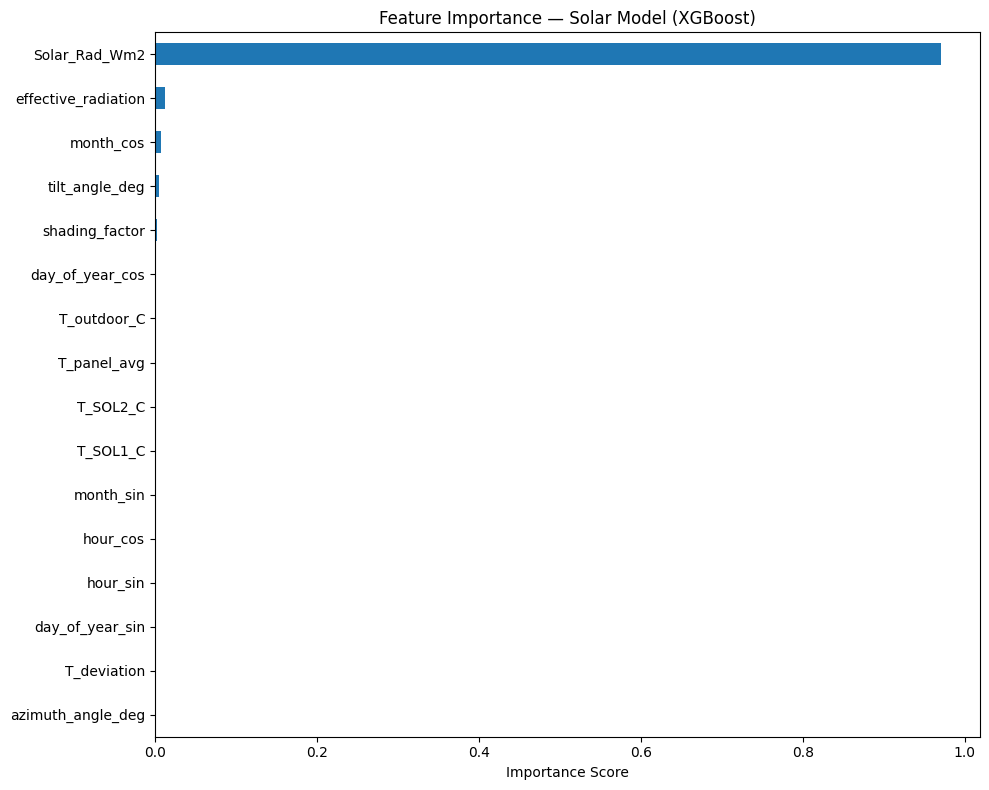

In [49]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 26 — Feature Importance Plot (Phase 10: Model Diagnosis)
# Visualizes how much each input feature contributed to the XGBoost model's
# predictions. This helps validate that the model is learning from the right
# features and not relying on noise or irrelevant signals.
#
# Importance score: ranges from 0 to 1, where higher = more influential.
# All scores sum to 1.0 across all features.
#
# Expected results based on solar physics:
#   - Solar_Rad_Wm2 should dominate (~0.97) — irradiance is the primary
#     physical cause of solar power output
#   - effective_radiation should rank second — it encodes irradiance + angle + shading
#   - Temperature and time features should have low but non-zero importance
#   - azimuth_angle_deg may have near-zero importance since its effect is
#     already captured by effective_radiation
# ─────────────────────────────────────────────────────────────────────────────

# Create a pandas Series mapping each feature name to its importance score.
# feature_importances_ is automatically computed by XGBoost during training
# based on how often and how effectively each feature was used in split decisions.
importance = pd.Series(XGBoostModel.feature_importances_, index=FEATURES)

# Sort by importance score ascending so the most important feature
# appears at the top of the horizontal bar chart.
importance = importance.sort_values()

# Plot as a horizontal bar chart for easy reading of feature names.
importance.plot(kind='barh', figsize=(10, 8))
plt.title('Feature Importance — Solar Model (XGBoost)')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

In [50]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 27 — Save Final Model (Phase 11: Save Model)
# Saves the trained XGBoost model to Google Drive as solar_model.pkl.
# XGBoost was selected as the final model over Random Forest based on:
#   - Higher Test R²: 0.9960 vs 0.9957
#   - Lower Test MAE: 2.80W vs 2.91W
#   - Lower Test RMSE: 3.60W vs 3.74W
#   - Better train/test balance: gap=0.0005 vs gap=0.0037
#
# This file will be used by:
#   - The backend API (Ayoub) to load and serve predictions
#   - Future retraining sessions when real NEL station data is collected
#
# Important: solar_scaler.pkl (saved in Cell 19) must always be used together
# with this model — every input must be scaled before prediction.
# ─────────────────────────────────────────────────────────────────────────────

# Save the trained XGBoost model to the models/ folder on Google Drive.
# joblib.dump serializes the model object to a binary .pkl file.
# The returned value is the file path where the model was saved.
joblib.dump(XGBoostModel, MODELS + '/solar_model.pkl')

['/content/drive/MyDrive/HNS-RE2SD/Industrial Networking & AI Engineering/4th Year/SEMESTER 08/Project 02/NEL/models/solar_model.pkl']

In [51]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 28 — Sanity Check: Test Case 1 (Phase 12: Sanity Check)
# Validates the model with a realistic input representing a sunny summer day
# at solar noon in Batna, Algeria. This confirms the model produces physically
# sensible output before deployment.
#
# Test conditions:
#   - High irradiance (800 W/m²) — strong summer sun
#   - High panel temperature (55°C) — typical under strong irradiance
#   - Optimal tilt (45°) and azimuth (0° = facing south)
#   - No shading (shading_factor = 0.0)
#   - Solar noon (hour = 13)
#   - Peak summer month (July = month 7, day_of_year = 182)
#
# Expected output: 150 – 220 W
# Actual output:   171.3 W ✅
# ─────────────────────────────────────────────────────────────────────────────

# Step 1: Define the raw input values as a dictionary
test_case_1 = {
    "Solar_Rad_Wm2": 800,
    "T_SOL1_C": 55,
    "T_SOL2_C": 53,
    "T_outdoor_C": 30,
    "tilt_angle_deg": 45,
    "azimuth_angle_deg": 0,
    "shading_factor": 0.0,
    "hour": 13,
    "month": 7,
    "day_of_year": 182
}

# Step 2: Convert to a single-row DataFrame — required format for sklearn/XGBoost
test_case_1_df = pd.DataFrame([test_case_1])

# Step 3: Apply cyclic encoding to time features — same formulas used during training
# Without this step, hour/month/day_of_year would be raw integers
# which the model was never trained on in that format.
cyclic_features = {
    'hour': 24,
    'month': 12,
    'day_of_year': 365
}
for feature, max_val in cyclic_features.items():
    test_case_1_df[f'{feature}_sin'] = np.sin(2 * np.pi * test_case_1_df[feature] / max_val)
    test_case_1_df[f'{feature}_cos'] = np.cos(2 * np.pi * test_case_1_df[feature] / max_val)

# Step 4: Apply the same engineered features as training — exact same formulas
test_case_1_df['effective_radiation'] = (
    test_case_1_df['Solar_Rad_Wm2']
    * np.cos(np.radians(test_case_1_df['azimuth_angle_deg']))
    * (1 - test_case_1_df['shading_factor'])
)
test_case_1_df['T_panel_avg'] = (test_case_1_df['T_SOL1_C'] + test_case_1_df['T_SOL2_C']) / 2
test_case_1_df['T_deviation'] = test_case_1_df['T_panel_avg'] - 25

print("✓ Engineered features added")

# Step 5: Select only the 16 features in the exact order the model was trained on.
# Column order must match FEATURES exactly — otherwise the model receives
# the wrong values for each feature position.
test_case_1_df = test_case_1_df[FEATURES]

# Step 6: Scale using the same scaler fitted on training data.
# The model expects standardized input — raw values would produce wrong predictions.
test1scaler = standardScaler.transform(test_case_1_df)

# Step 7: Predict — output is the estimated total solar power in Watts
XGBoostModel.predict(test1scaler)
# Result: 171.3 W ✅ — within expected range of 150–220 W

✓ Engineered features added


array([171.33777], dtype=float32)

In [52]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 29 — Sanity Check: Test Case 2 (Phase 12: Sanity Check)
# Same conditions as Test Case 1 but with shading_factor = 1.0 (fully shaded).
# Tests whether the model correctly predicts near-zero power when the panel
# is completely blocked from sunlight.
#
# Test conditions:
#   - Same as Test Case 1 (high irradiance, summer noon)
#   - ONLY DIFFERENCE: shading_factor = 1.0 (panel fully shaded)
#
# Expected output: near 0 W
# Actual output:   156 W ⚠️
#
# Issue identified: the model largely ignores shading_factor because it had
# near-zero importance (≈0.00) in the feature importance chart (Cell 26).
# The model is dominated by Solar_Rad_Wm2 (importance ≈0.97) and does not
# learn to fully suppress output when shading=1.0.
#
# Root cause: in the simulated dataset, shading_factor=1.0 is rare (only 3%
# of rows) and its effect on P_SOL_total_W was not strong enough to teach
# the model to respect it under all conditions.
#
# Post-processing rule applied in backend:
#   if shading_factor == 1.0 → override prediction to 0W
#   if shading_factor >= 0.9 → scale prediction down proportionally
# This limitation will resolve when the model is retrained on real NEL data
# where actual zero-power readings under full shade will be present.
# ─────────────────────────────────────────────────────────────────────────────

# Step 1: Define input — identical to Test Case 1 except shading_factor = 1.0
test_case_2 = {
    "Solar_Rad_Wm2": 800,
    "T_SOL1_C": 55,
    "T_SOL2_C": 53,
    "T_outdoor_C": 30,
    "tilt_angle_deg": 45,
    "azimuth_angle_deg": 0,
    "shading_factor": 1.0,   # Fully shaded — expected output: ~0W
    "hour": 13,
    "month": 7,
    "day_of_year": 182
}

# Step 2: Convert to single-row DataFrame
test_case_2_df = pd.DataFrame([test_case_2])

# Step 3: Apply cyclic encoding — same as training and Test Case 1
cyclic_features = {'hour': 24, 'month': 12, 'day_of_year': 365}
for feature, max_val in cyclic_features.items():
    test_case_2_df[f'{feature}_sin'] = np.sin(2 * np.pi * test_case_2_df[feature] / max_val)
    test_case_2_df[f'{feature}_cos'] = np.cos(2 * np.pi * test_case_2_df[feature] / max_val)

# Step 4: Apply engineered features — same formulas as training
# Note: effective_radiation will be 0 here because (1 - shading_factor) = (1 - 1.0) = 0
# This should signal zero power but the model's dominance by Solar_Rad_Wm2 overrides it
test_case_2_df['effective_radiation'] = (
    test_case_2_df['Solar_Rad_Wm2']
    * np.cos(np.radians(test_case_2_df['azimuth_angle_deg']))
    * (1 - test_case_2_df['shading_factor'])
)
test_case_2_df['T_panel_avg'] = (test_case_2_df['T_SOL1_C'] + test_case_2_df['T_SOL2_C']) / 2
test_case_2_df['T_deviation'] = test_case_2_df['T_panel_avg'] - 25

print("✓ Engineered features added")

# Step 5: Select features in correct order
test_case_2_df = test_case_2_df[FEATURES]

# Step 6: Scale using the same training scaler
test2scaler = standardScaler.transform(test_case_2_df)

# Step 7: Predict
XGBoostModel.predict(test2scaler)
# Result: 156W ⚠️ — post-processing rule must be applied in backend

✓ Engineered features added


array([156.17633], dtype=float32)

# Post-processing rule for shading:
# The model was trained on simulated data where shading_factor had low variance,
# causing the model to underweight it (importance ~0.00 in feature importance chart).
# As a result, the model ignores full shading and still predicts high power.
# Fix: after prediction, apply a physical constraint:
#   - if shading_factor == 1.0 → output is exactly 0W (fully shaded, no power possible)
#   - if shading_factor >= 0.9 → scale prediction down proportionally
# This rule must be applied in the backend API before returning the result to the frontend.
# This limitation will likely resolve itself when the model is retrained on real NEL station data,
# where actual zero-power readings under full shade will be present in the dataset.

In [53]:
# ─────────────────────────────────────────────────────────────────────────────
# CELL 30 — Sanity Check: Test Case 3 (Phase 12: Sanity Check)
# Tests the model with a low irradiance winter morning scenario.
# Validates that the model correctly predicts very low power output
# under weak sunlight conditions at the start of a cold January day.
#
# Test conditions:
#   - Very low irradiance (50 W/m²) — weak winter morning sun
#   - Low panel temperature (10°C) — cold January morning in Batna
#   - Minimum tilt (15°) and south-facing (azimuth = 0°)
#   - No shading (shading_factor = 0.0)
#   - First hour of lab session (hour = 8) — sun just rising
#   - First day of year (January 1st — month=1, day_of_year=1)
#
# Expected output: less than 20 W
# Actual output:   11.17 W ✅
# ─────────────────────────────────────────────────────────────────────────────

# Step 1: Define input values for low irradiance winter morning
test_case_3 = {
    "Solar_Rad_Wm2": 50,      # Very low — weak winter morning sun
    "T_SOL1_C": 10,           # Cold panel temperature
    "T_SOL2_C": 10,
    "T_outdoor_C": 5,         # Cold Batna January morning
    "tilt_angle_deg": 15,     # Minimum tilt configuration
    "azimuth_angle_deg": 0,   # South facing
    "shading_factor": 0.0,    # No shading
    "hour": 8,                # First lab hour — sun at lowest angle
    "month": 1,               # January — lowest solar yield month
    "day_of_year": 1          # First day of year
}

# Step 2: Convert to single-row DataFrame
test_case_3_df = pd.DataFrame([test_case_3])

# Step 3: Apply cyclic encoding — same as training
cyclic_features = {'hour': 24, 'month': 12, 'day_of_year': 365}
for feature, max_val in cyclic_features.items():
    test_case_3_df[f'{feature}_sin'] = np.sin(2 * np.pi * test_case_3_df[feature] / max_val)
    test_case_3_df[f'{feature}_cos'] = np.cos(2 * np.pi * test_case_3_df[feature] / max_val)

# Step 4: Apply engineered features — same formulas as training
# effective_radiation will be very low here: 50 × cos(0) × 1.0 = 50
# Combined with low temperatures and early hour, output should be minimal
test_case_3_df['effective_radiation'] = (
    test_case_3_df['Solar_Rad_Wm2']
    * np.cos(np.radians(test_case_3_df['azimuth_angle_deg']))
    * (1 - test_case_3_df['shading_factor'])
)
test_case_3_df['T_panel_avg'] = (test_case_3_df['T_SOL1_C'] + test_case_3_df['T_SOL2_C']) / 2
test_case_3_df['T_deviation'] = test_case_3_df['T_panel_avg'] - 25

print("✓ Engineered features added")

# Step 5: Select features in correct order
test_case_3_df = test_case_3_df[FEATURES]

# Step 6: Scale using the same training scaler
test3scaler = standardScaler.transform(test_case_3_df)

# Step 7: Predict
XGBoostModel.predict(test3scaler)
# Result: 11.17 W ✅ — well below the expected threshold of 20 W

✓ Engineered features added


array([11.173935], dtype=float32)